In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

np.random.seed(42)
tf.random.set_seed(42)

# Load dataset AKRA.csv (kalau belum ada di Colab, akan muncul tombol upload)
try:
    df = pd.read_csv("AKRA.csv", parse_dates=["date"])
except FileNotFoundError:
    from google.colab import files
    files.upload()
    df = pd.read_csv("AKRA.csv", parse_dates=["date"])

df = df.sort_values("date").reset_index(drop=True)
print("Jumlah baris:", len(df))
print("Rentang tanggal:", df["date"].min().date(), "s/d", df["date"].max().date())
df[["date", "open_price", "high", "low", "close", "volume"]].head()

Saving AKRA.csv to AKRA.csv
Jumlah baris: 1355
Rentang tanggal: 2019-07-29 s/d 2025-02-21


,date,open_price,high,low,close,volume
0,2019-07-29,4000.0,4000.0,3880.0,3880.0,7699400.0
1,2019-07-30,3910.0,3940.0,3850.0,3930.0,7052000.0
2,2019-07-31,3910.0,4010.0,3910.0,4000.0,6624600.0
3,2019-08-01,3980.0,4000.0,3900.0,4000.0,5410500.0
4,2019-08-02,3990.0,4060.0,3940.0,4060.0,7104900.0


Nilai kosong pada kolom close: 0
Tanggal split: 2022-01-12 | rasio 1 : 5


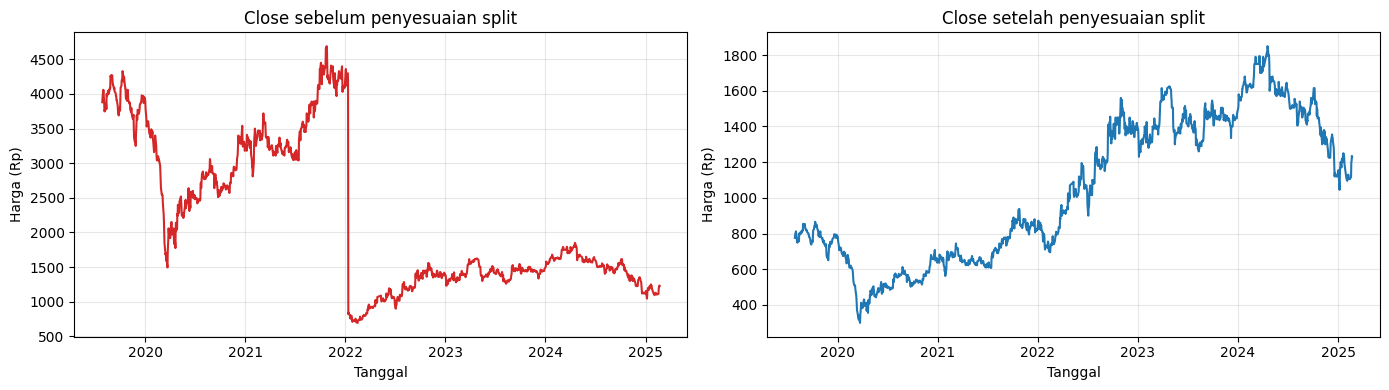

In [5]:
print("Nilai kosong pada kolom close:", df["close"].isna().sum())

# Deteksi tanggal split dari perubahan jumlah saham beredar
split_idx = df.index[df["listed_shares"].diff() > 0.5 * df["listed_shares"].shift()][0]
ratio = round(df.loc[split_idx, "listed_shares"] / df.loc[split_idx - 1, "listed_shares"])
print("Tanggal split:", df.loc[split_idx, "date"].date(), "| rasio 1 :", ratio)

df["close_adj"] = df["close"]
df.loc[:split_idx - 1, "close_adj"] = df.loc[:split_idx - 1, "close"] / ratio

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(df["date"], df["close"], color="tab:red")
ax[0].set_title("Close sebelum penyesuaian split")
ax[1].plot(df["date"], df["close_adj"], color="tab:blue")
ax[1].set_title("Close setelah penyesuaian split")
for a in ax:
    a.set_xlabel("Tanggal"); a.set_ylabel("Harga (Rp)"); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
prices = df["close_adj"].values.reshape(-1, 1)

# 80% latih, 20% uji (urut waktu, tidak diacak)
window = 60                       # jumlah hari ke belakang sebagai input
train_size = int(len(prices) * 0.8)

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(prices[:train_size])   # fit hanya pada data latih
scaled = scaler.transform(prices)

print("Data latih:", train_size, "| Data uji:", len(prices) - train_size)

Data latih: 1084 | Data uji: 271


In [7]:
def buat_sekuens(data, window):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i - window:i, 0])
        y.append(data[i, 0])
    return np.array(X).reshape(-1, window, 1), np.array(y)

# Data uji ikut mengambil 'window' hari terakhir dari data latih sebagai konteks
X_train, y_train = buat_sekuens(scaled[:train_size], window)
X_test,  y_test  = buat_sekuens(scaled[train_size - window:], window)

test_dates = df["date"].iloc[train_size:].reset_index(drop=True)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

X_train: (1024, 60, 1) | y_train: (1024,)
X_test : (271, 60, 1) | y_test : (271,)


In [8]:
def buat_model():
    model = Sequential([
        Input(shape=(window, 1)),
        LSTM(50, return_sequences=True),
        LSTM(50),
        Dense(25, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

buat_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
hasil = {}
for ep in [10, 100]:
    tf.random.set_seed(42)
    model = buat_model()
    hist = model.fit(X_train, y_train, epochs=ep, batch_size=32,
                     validation_split=0.1, verbose=0)

    pred_scaled = model.predict(X_test, verbose=0)
    pred = scaler.inverse_transform(pred_scaled).ravel()
    aktual = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

    rmse = np.sqrt(mean_squared_error(aktual, pred))
    mae  = mean_absolute_error(aktual, pred)
    mape = np.mean(np.abs((aktual - pred) / aktual)) * 100

    # Prediksi hari berikutnya (setelah data terakhir)
    last = scaled[-window:].reshape(1, window, 1)
    next_price = scaler.inverse_transform(model.predict(last, verbose=0))[0, 0]

    hasil[ep] = dict(model=model, hist=hist.history, pred=pred, aktual=aktual,
                     rmse=rmse, mae=mae, mape=mape, next_price=next_price)
    print(f"Epoch {ep:>3} | Train loss: {hist.history['loss'][-1]:.6f} | "
          f"Val loss: {hist.history['val_loss'][-1]:.6f} | RMSE: {rmse:.2f} | "
          f"MAE: {mae:.2f} | MAPE: {mape:.2f}%")

Epoch  10 | Train loss: 0.001475 | Val loss: 0.001473 | RMSE: 65.48 | MAE: 52.10 | MAPE: 3.72%
Epoch 100 | Train loss: 0.000401 | Val loss: 0.000522 | RMSE: 34.47 | MAE: 26.45 | MAPE: 1.85%


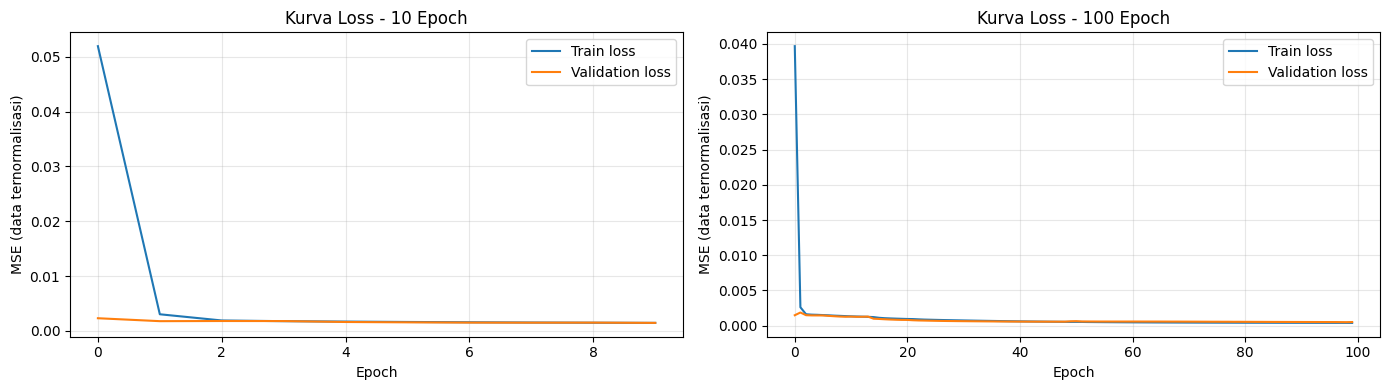

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, ep in zip(ax, [10, 100]):
    h = hasil[ep]["hist"]
    a.plot(h["loss"], label="Train loss")
    a.plot(h["val_loss"], label="Validation loss")
    a.set_title(f"Kurva Loss - {ep} Epoch")
    a.set_xlabel("Epoch"); a.set_ylabel("MSE (data ternormalisasi)")
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

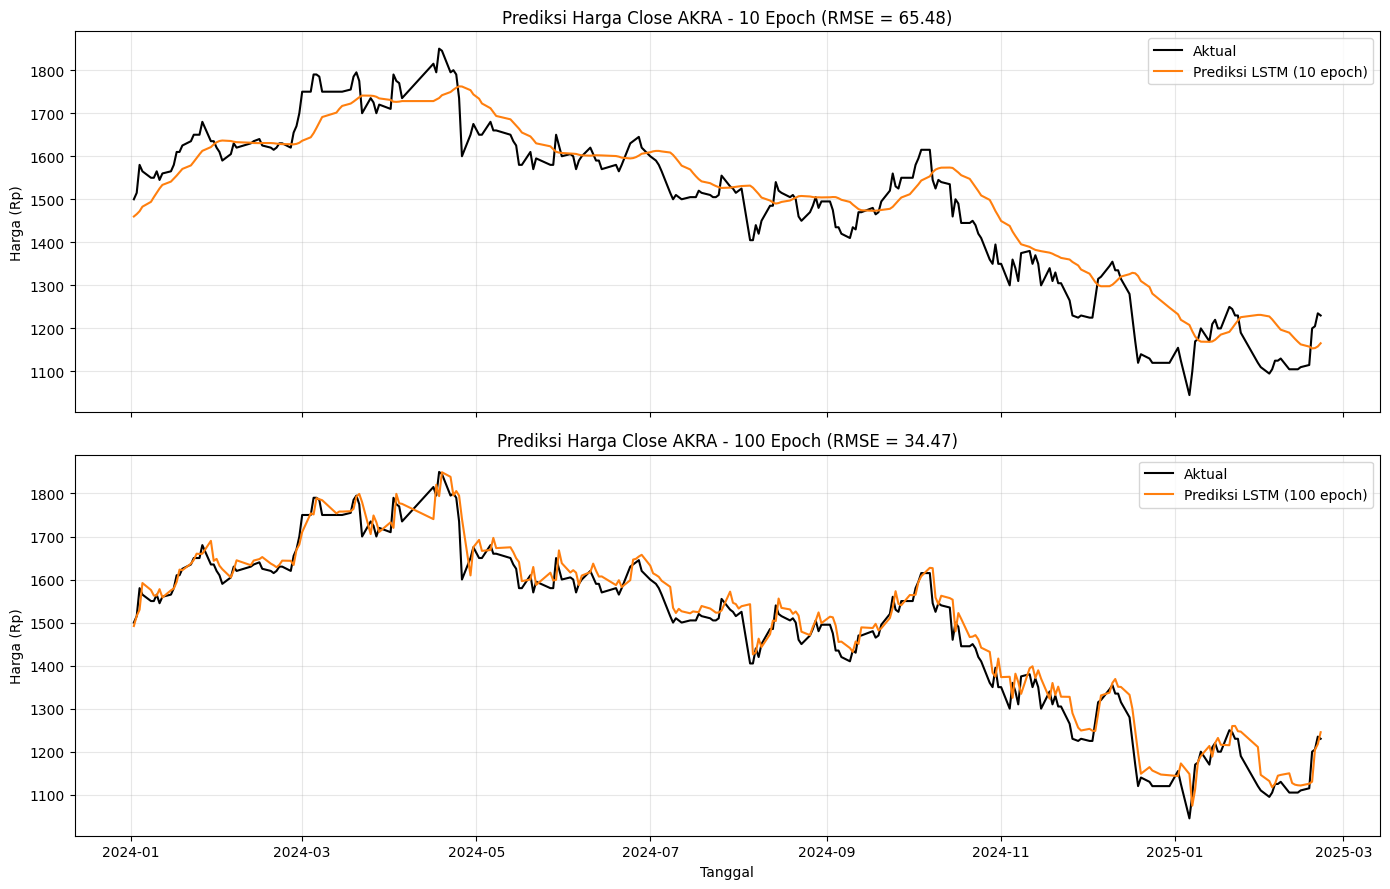

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for a, ep in zip(ax, [10, 100]):
    a.plot(test_dates, hasil[ep]["aktual"], label="Aktual", color="black")
    a.plot(test_dates, hasil[ep]["pred"], label=f"Prediksi LSTM ({ep} epoch)", color="tab:orange")
    a.set_title(f"Prediksi Harga Close AKRA - {ep} Epoch (RMSE = {hasil[ep]['rmse']:.2f})")
    a.set_ylabel("Harga (Rp)")
    a.legend(); a.grid(alpha=0.3)
ax[1].set_xlabel("Tanggal")
plt.tight_layout()
plt.show()

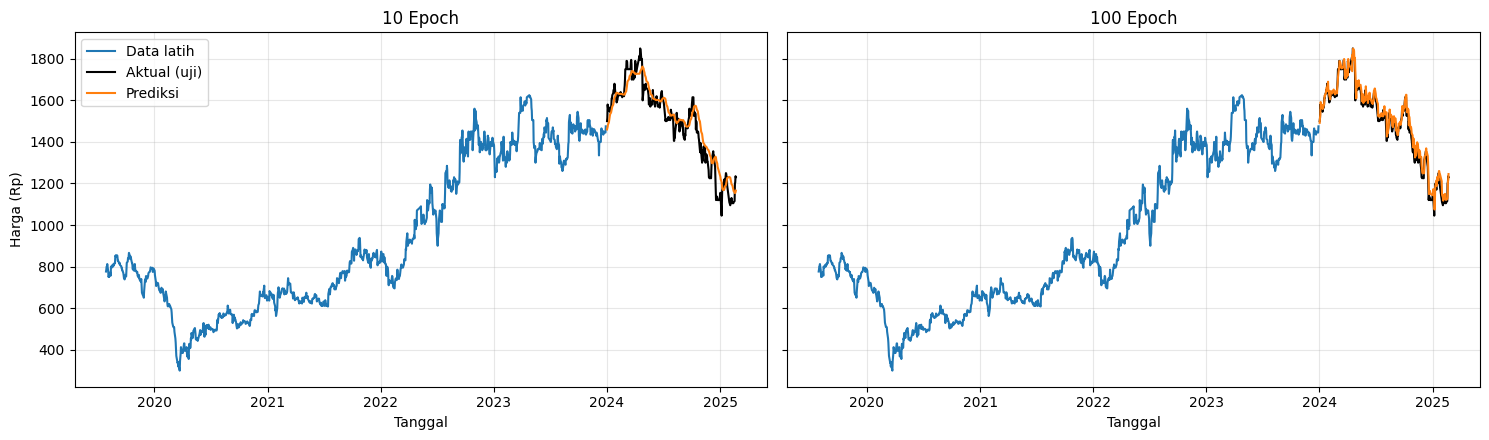

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, ep in zip(ax, [10, 100]):
    a.plot(df["date"].iloc[:train_size], prices[:train_size], label="Data latih", color="tab:blue")
    a.plot(test_dates, hasil[ep]["aktual"], label="Aktual (uji)", color="black")
    a.plot(test_dates, hasil[ep]["pred"], label="Prediksi", color="tab:orange")
    a.set_title(f"{ep} Epoch")
    a.set_xlabel("Tanggal"); a.grid(alpha=0.3)
ax[0].set_ylabel("Harga (Rp)"); ax[0].legend()
plt.tight_layout()
plt.show()

In [14]:
ringkasan = pd.DataFrame({
    "Epoch": [10, 100],
    "Train loss": [hasil[e]["hist"]["loss"][-1] for e in (10, 100)],
    "Val loss":   [hasil[e]["hist"]["val_loss"][-1] for e in (10, 100)],
    "RMSE (Rp)":  [hasil[e]["rmse"] for e in (10, 100)],
    "MAE (Rp)":   [hasil[e]["mae"] for e in (10, 100)],
    "MAPE (%)":   [hasil[e]["mape"] for e in (10, 100)],
    "Prediksi hari berikutnya (Rp)": [hasil[e]["next_price"] for e in (10, 100)],
}).round(4)
print("Harga close terakhir di dataset (", df['date'].iloc[-1].date(), "): Rp", df['close_adj'].iloc[-1])
ringkasan

Harga close terakhir di dataset ( 2025-02-21 ): Rp 1230.0


,Epoch,Train loss,Val loss,RMSE (Rp),MAE (Rp),MAPE (%),Prediksi hari berikutnya (Rp)
0,10,0.0015,0.0015,65.4789,52.1029,3.7156,1174.624756
1,100,0.0004,0.0005,34.4682,26.4497,1.8532,1243.017822


In [15]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=ringkasan)

https://docs.google.com/spreadsheets/d/1eadtGFX4U7PwI7FMADlRE1rOCSzRfef7r5i7V0J1yAU/edit#gid=0
